# Learning from Very Little

*The Mathematics of Machine Intelligence · Chapter 11*

Turn one or two examples into a confident answer, and see what the confidence costs.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Use these ideas to ask what prior a confident answer rests on, to choose a test case that separates rival rules, and to read a one-shot result without crediting the whole gap to the prior.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 11, Learning from Very Little: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def odds_text(value):
    """Odds written as 'q to 1' (or '1 to q' when below one)."""
    if value >= 1:
        return f'{sig(value)} to 1'
    return f'1 to {sig(1 / value)}'

def posterior_odds(likelihood_ratio, prior_odds):
    """Bayes' rule in odds form for two candidates."""
    if likelihood_ratio < 0 or prior_odds <= 0:
        raise ValueError('The likelihood ratio must be nonnegative and the prior odds positive.')
    return likelihood_ratio * prior_odds

def odds_to_probability(odds):
    """Probability of the first candidate when the two exclude each other and exhaust the cases."""
    return odds / (1 + odds)
PRIOR_ODDS_VALUES = [1 / 9, 1 / 3, 2 / 3, 1, 3, 9]
PRIOR_ODDS_LABELS = ['1 to 9', '1 to 3', '2 to 3', '1 to 1', '3 to 1', '9 to 1']

def bayes_odds_picture(likelihood_ratio=9, prior_odds=1):
    post = posterior_odds(likelihood_ratio, prior_odds)
    p_prior, p_post = (odds_to_probability(prior_odds), odds_to_probability(post))
    fig, ax = panels()
    bars = ax[0].bar(['before the\npicture', 'after the\npicture'], [p_prior, p_post], color=[GREY, TEAL], width=0.55)
    for bar, v in zip(bars, [p_prior, p_post]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.03, sig(v), va='bottom')
    ax[0].set(ylabel='chance of candidate A (A and B only)', title='Evidence moves the odds', ylim=(0, 1.25))
    tag(ax[0], 0.5, 0.96, f'odds {odds_text(prior_odds)}  x  {sig(likelihood_ratio)}  =  {odds_text(post)}', transform=ax[0].transAxes, fontsize=9, color=NAVY)
    grid = np.geomspace(1, 100, 100)
    for prior, label, style, colour in [(1 / 9, 'prior 1 to 9', 'dotted', GREY), (1, 'prior 1 to 1', 'dashed', TEAL), (9, 'prior 9 to 1', 'dashdot', TERRA)]:
        ax[1].plot(grid, grid * prior, color=colour, linestyle=style, linewidth=1.5, label=label)
    ax[1].plot(grid, grid * prior_odds, color=NAVY, linewidth=3, label='selected prior')
    ring(ax[1], likelihood_ratio, post)
    ax[1].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xticks([1, 3, 9, 30, 100])
    ax[1].set_xticklabels(['1', '3', '9', '30', '100'])
    ax[1].set_yticks([0.1, 1, 10, 100, 1000])
    ax[1].set_yticklabels(['0.1', '1', '10', '100', '1000'])
    ax[1].set(xlabel='likelihood ratio (A explains the picture how many times better)', ylabel='odds of A to B after the picture', title='Odds multiply', ylim=(0.07, 1400))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Prior odds': odds_text(prior_odds), 'Likelihood ratio': sig(likelihood_ratio), 'Odds after the picture': odds_text(post), 'Chance of A after the picture': sig(p_post)}
    summary = f'Candidate A explains the picture {sig(likelihood_ratio)} times as well as B and starts at odds {odds_text(prior_odds)}, so the odds after the picture are {odds_text(post)}. If A and B are the only cases, that is a chance of {sig(p_post)} for A, up from {sig(p_prior)}.'
    calc = f'Posterior odds = likelihood ratio x prior odds = {sig(likelihood_ratio)} x {sig(prior_odds)} = {sig(post)}. Probability = odds/(1 + odds) = {sig(post)}/{sig(1 + post)} = {sig(p_post)}, valid only when A and B exclude each other and exhaust the cases.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
STEADY_FLIP, SHAKY_FLIP, CELLS_EACH = (0.05, 0.3, 20)

def differ_probability(flip):
    """Chance two independent redraws differ on a cell when each redraw flips the cell with chance `flip`."""
    return 2 * flip * (1 - flip)

def cell_weight(flip):
    """Log of how much more often a cell agrees than disagrees between twins."""
    d = differ_probability(flip)
    return math.log((1 - d) / d)

def penalties(steady_misses_1, shaky_misses_2):
    """Counting and weighted penalties for candidate 1 (misses on steady cells) and candidate 2 (misses on shaky cells)."""
    ws, wk = (cell_weight(STEADY_FLIP), cell_weight(SHAKY_FLIP))
    return {'count': (steady_misses_1, shaky_misses_2), 'weighted': (steady_misses_1 * ws, shaky_misses_2 * wk), 'ws': ws, 'wk': wk}

def winner(a, b):
    if a < b - 1e-12:
        return 'candidate 1'
    if b < a - 1e-12:
        return 'candidate 2'
    return 'a tie'

def weighing_picture(steady_misses=2, shaky_misses=8):
    p = penalties(steady_misses, shaky_misses)
    ws, wk = (p['ws'], p['wk'])
    w1, w2 = p['weighted']
    count_win, weigh_win = (winner(steady_misses, shaky_misses), winner(w1, w2))
    fig, ax = panels()
    xs = np.arange(2)
    width = 0.36
    b1 = ax[0].bar(xs - width / 2, [steady_misses, shaky_misses], width, color=GREY, label='counting (misses)')
    b2 = ax[0].bar(xs + width / 2, [w1, w2], width, color=TEAL, label='weighing (penalty)')
    top = max(steady_misses, shaky_misses, w1, w2, 1) * 1.28
    for bars in (b1, b2):
        for bar in bars:
            tag(ax[0], bar.get_x() + bar.get_width() / 2, bar.get_height() + top * 0.02, sig(bar.get_height()), va='bottom')
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels([f'candidate 1\n{steady_misses} steady misses', f'candidate 2\n{shaky_misses} shaky misses'], fontsize=9)
    ax[0].set(ylabel='penalty (lower wins)', title=f'Counting: {count_win}. Weighing: {weigh_win}.', ylim=(0, top))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2)
    xx = np.linspace(0, 13, 100)
    ax[1].fill_between(xx, xx * wk / ws, xx, color=GOLD, alpha=0.25, label='counting and weighing disagree')
    ax[1].plot(xx, xx, color=GREY, linewidth=1.6, linestyle='dashed', label='counting tie: y = x')
    ax[1].plot(xx, xx * wk / ws, color=NAVY, linewidth=1.8, label=f'weighing tie: y = {wk / ws:.3f} x')
    gx, gy = np.meshgrid([2, 4, 6, 8, 10, 12], [1, 2, 3, 4])
    ax[1].plot(gx.ravel(), gy.ravel(), linestyle='none', marker='o', markersize=4, color=GREY)
    ring(ax[1], shaky_misses, steady_misses)
    ax[1].set(xlabel='misses of candidate 2 (shaky cells)', ylabel='misses of candidate 1 (steady cells)', title='Where the two rules disagree', xlim=(0, 13), ylim=(0, 4.6))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    metrics = {'Weight on a steady cell': sig(ws), 'Weight on a shaky cell': sig(wk), 'Penalty, candidate 1 / candidate 2': f'{sig(w1)} / {sig(w2)}', 'Weighing picks': weigh_win}
    summary = f'A miss on a steady cell costs {sig(ws)} and on a shaky cell {sig(wk)}. Candidate 1 has {steady_misses} steady misses and candidate 2 has {shaky_misses} shaky ones, so counting picks {count_win} and weighing picks {weigh_win}. This is a constructed toy, not data.'
    calc = f'Steady cells flip {STEADY_FLIP:g} of the time, so twins differ with chance 2 x {STEADY_FLIP:g} x {1 - STEADY_FLIP:g} = {sig(differ_probability(STEADY_FLIP))} and the weight is ln({sig(1 - differ_probability(STEADY_FLIP))}/{sig(differ_probability(STEADY_FLIP))}) = {sig(ws)}. Shaky cells: 2 x {SHAKY_FLIP:g} x {1 - SHAKY_FLIP:g} = {sig(differ_probability(SHAKY_FLIP))}, weight {sig(wk)}. Penalties: {steady_misses} x {sig(ws)} = {sig(w1)} and {shaky_misses} x {sig(wk)} = {sig(w2)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SIM_TRIALS = 40000
SHAKY_VALUES = [0.05, 0.1, 0.2, 0.3, 0.4]

@lru_cache(maxsize=None)
def simulate_trials(shaky_flip, candidates, trials=SIM_TRIALS, seed=None):
    """Error rates (fractions) of counting and of steadiness weighting on one-shot picks among `candidates`.

    Characters are independent 40-cell grids, 20 cells flipping with chance 0.05 and 20 with `shaky_flip` between drawings.
    The picture and its twin are two redraws of one character; the other candidates are redraws of unrelated characters.
    Ties are broken by one random key shared by both methods, so equal weights give identical results.
    """
    if seed is None:
        seed = 11000 + int(round(shaky_flip * 100)) * 10 + candidates
    rng = np.random.default_rng(seed)
    flip = np.array([STEADY_FLIP] * CELLS_EACH + [shaky_flip] * CELLS_EACH)
    base = rng.integers(0, 2, (trials, 1, 2 * CELLS_EACH), dtype=np.uint8)
    picture = base[:, 0, :] ^ (rng.random((trials, 2 * CELLS_EACH)) < flip)
    twin = base[:, 0, :] ^ (rng.random((trials, 2 * CELLS_EACH)) < flip)
    others = rng.integers(0, 2, (trials, candidates - 1, 2 * CELLS_EACH), dtype=np.uint8)
    cands = np.concatenate([twin[:, None, :], others], axis=1)
    misses = cands != picture[:, None, :]
    weights = np.array([cell_weight(STEADY_FLIP)] * CELLS_EACH + [cell_weight(shaky_flip)] * CELLS_EACH)
    jitter = rng.random((trials, candidates)) * 1e-09
    out = []
    for score in (misses.sum(axis=2) + jitter, (misses * weights).sum(axis=2) + jitter):
        out.append(float(np.mean(score.argmin(axis=1) != 0)))
    return (out[0], out[1])

def simulation_picture(shaky_flip=0.3, candidates=20):
    count_err, weigh_err = simulate_trials(shaky_flip, candidates)
    chance = 1 - 1 / candidates
    fig, ax = panels()
    bars = ax[0].bar(['counting\nagreements', 'weighing by\nsteadiness'], [100 * count_err, 100 * weigh_err], color=[GREY, TEAL], width=0.55)
    top = max(100 * count_err, 100 * weigh_err, 1) * 1.3
    for bar in bars:
        tag(ax[0], bar.get_x() + bar.get_width() / 2, bar.get_height() + top * 0.02, f'{bar.get_height():.1f}', va='bottom')
    ax[0].set(ylabel='wrong picks (percent of trials)', title=f'Pick the twin among {candidates} ({SIM_TRIALS:,} trials)', ylim=(0, top))
    for colour, style, index, label in [(GREY, 'dashed', 0, 'counting'), (TEAL, 'solid', 1, 'weighing')]:
        curve = [100 * simulate_trials(s, candidates)[index] for s in SHAKY_VALUES]
        ax[1].plot(SHAKY_VALUES, curve, color=colour, linestyle=style, linewidth=2, marker='o', markersize=4, label=label)
    ring(ax[1], shaky_flip, 100 * count_err)
    ring(ax[1], shaky_flip, 100 * weigh_err)
    ax[1].set(xlabel='flip chance of the 20 shaky cells (steady cells: 0.05)', ylabel='wrong picks (percent)', title=f'Weighing helps as cells differ in steadiness ({candidates} candidates)')
    ax[1].title.set_fontsize(9)
    ax[1].legend(fontsize=9, loc='upper left')
    ratio = 'undefined (no wrong picks when weighing)' if weigh_err == 0 else sig(count_err / weigh_err)
    metrics = {'Counting, wrong picks (percent)': f'{100 * count_err:.1f}', 'Weighing, wrong picks (percent)': f'{100 * weigh_err:.1f}', 'Random pick would be wrong (percent)': f'{100 * chance:.0f}', 'Counting errors per weighing error': ratio}
    summary = f'In this seeded simulation of {SIM_TRIALS:,} trials, counting agreements picks the wrong twin {100 * count_err:.1f} percent of the time and weighing by steadiness {100 * weigh_err:.1f} percent, with shaky cells flipping {shaky_flip:g} of the time. The chapter reports about 10.6 and 1.6 percent for 20 candidates and 0.30; this run is a constructed model, not a measurement.'
    calc = f'Weights: steady {sig(cell_weight(STEADY_FLIP))}, shaky {sig(cell_weight(shaky_flip))}. Each trial draws one 40-cell character, two redraws (picture and twin) and {candidates - 1} unrelated grids; the lowest total penalty wins and ties are broken at random. Equal flip chances (0.05 and 0.05) give equal weights, so the two methods then agree exactly.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PEOPLE_ERROR, CHANCE_ERROR = (4.5, 95.0)
SCENARIOS = {'30 alphabets': ('30 alphabets', 3.3, 13.5), 'five alphabets, first set': ('five alphabets,\nfirst set', 4.3, 24.0), 'five alphabets, second set': ('five alphabets,\nsecond set', 4.0, 22.3), '30 alphabets, copy variation tripled': ('30 alphabets, copy\nvariation tripled', 11.0, 13.5), '30 alphabets, stroke learning removed': ('30 alphabets, stroke\nlearning removed', 3.5, 13.5)}

def omniglot_picture(scenario='30 alphabets'):
    label, stroke, network = SCENARIOS[scenario]
    fig, ax = panels()
    vals = [PEOPLE_ERROR, stroke, network]
    bars = ax[0].bar(['people', 'stroke\nmodel', 'convolutional\nnetwork'], vals, color=[GOLD, TEAL, TERRA], width=0.6)
    for bar, v in zip(bars, vals):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.6, f'{v:g}', va='bottom')
    ax[0].set(ylabel='errors (percent)', title='One example, pick the twin of 20', ylim=(0, 29))
    tag(ax[0], 0.5, 0.93, 'random guessing: 95 percent wrong', transform=ax[0].transAxes, fontsize=9, color=GREY)
    names = list(SCENARIOS)
    ys = np.arange(len(names))[::-1]
    for y, name in zip(ys, names):
        _, s, n = SCENARIOS[name]
        ax[1].plot([s, n], [y, y], color=GREY, linewidth=1)
        ax[1].plot([s], [y], marker='o', markersize=7, color=TEAL, linestyle='none', label='stroke model' if y == ys[0] else None)
        ax[1].plot([n], [y], marker='s', markersize=7, color=TERRA, linestyle='none', label='convolutional network' if y == ys[0] else None)
    ring(ax[1], stroke, ys[names.index(scenario)])
    ax[1].axvline(PEOPLE_ERROR, color=DARK_GOLD, linestyle='dashed', linewidth=1.4, label='people, 4.5')
    ax[1].set_yticks(ys)
    ax[1].set_yticklabels([SCENARIOS[n][0] for n in names], fontsize=8)
    ax[1].set(xlabel='errors (percent)', title='Every reported case', xlim=(0, 27), ylim=(-0.6, len(names) - 0.4))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.4, -0.2), ncol=3)
    ratio = network / stroke
    metrics = {'Stroke model errors (percent)': f'{stroke:g}', 'Convolutional network errors (percent)': f'{network:g}', 'People errors (percent)': f'{PEOPLE_ERROR:g}', 'Network errors per stroke-model error': sig(ratio)}
    summary = f"Reported errors for {label.replace(chr(10), ' ')}: stroke model {stroke:g} percent, convolutional network {network:g} percent, people {PEOPLE_ERROR:g} percent. The chapter gives no split of how much each difference between the models mattered, and a lesion shows one learned part mattered, not that the whole prior did."
    calc = f"Network errors divided by stroke-model errors = {network:g}/{stroke:g} = {sig(ratio)}. In the lesion rows the network figure is its intact 13.5, and the stroke figure is the lesioned model's."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
GROUPS = {'no help': (356, 71, 'no help'), 'blurred objects': (417, 63, 'blurred moving objects'), 'video': (1144, 72, 'watched a video'), 'manual': (1848, 72, 'read a manual')}
DQN_FROSTBITE, RANDOM_FROSTBITE, HUMAN_FROSTBITE = (328.3, 65.2, 4335)

def normalized_score(score):
    """Scale of the 2015 deep Q-network paper: random play 0, a professional tester 100."""
    return 100 * (score - RANDOM_FROSTBITE) / (HUMAN_FROSTBITE - RANDOM_FROSTBITE)

def frostbite_picture(group='manual'):
    mean, count, label = GROUPS[group]
    base = GROUPS['no help'][0]
    ratio = mean / base
    fig, ax = panels()
    vals = [mean, base, DQN_FROSTBITE]
    bars = ax[0].bar([f'selected:\n{label}', 'no help', 'original deep\nQ-network (2015)'], vals, color=[TEAL, GREY, GOLD], width=0.6)
    for bar, v in zip(bars, vals):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 40, f'{int(v):,}' if v == int(v) else f'{v:g}', va='bottom')
    ax[0].set(ylabel='points in the first game', title='Mean first-game Frostbite score', ylim=(0, 2200))
    ax[0].tick_params(axis='x', labelsize=8)
    names = list(GROUPS)
    scores = [GROUPS[n][0] for n in names]
    bars = ax[1].bar(range(4), scores, color=[TEAL if n == group else GREY for n in names], width=0.6)
    for i, (bar, s) in enumerate(zip(bars, scores)):
        tag(ax[1], i, s + (130 if names[i] == group else 40), f'{s:,}  ({s / base:.1f}x)', va='bottom', fontsize=9)
    ring(ax[1], names.index(group), mean)
    ax[1].set_xticks(range(4))
    ax[1].set_xticklabels(['no help', 'blurred\nobjects', 'video\n(1:26)', 'manual'], fontsize=9)
    ax[1].set(ylabel='points in the first game', title='All four groups', ylim=(0, 2350))
    metrics = {'Mean first-game score': f'{mean:,}', 'Times the no-help score': sig(ratio), 'Players in the group': str(count), "On the 2015 paper's scale (companion's conversion)": f'{normalized_score(mean):.1f}'}
    summary = f"Players in the group '{label}' averaged {mean:,} points, {sig(ratio)} times the no-help {base}. The chapter reads the manual result as a hint that people build a model of the game, which is the authors' interpretation; no mechanism was measured. The original deep Q-network scored {DQN_FROSTBITE:g}, {normalized_score(DQN_FROSTBITE):.1f} on the 2015 scale."
    calc = f"Ratio = {mean:,}/{base} = {sig(ratio)}. Scale = 100 x (score - {RANDOM_FROSTBITE:g})/({HUMAN_FROSTBITE:,} - {RANDOM_FROSTBITE:g}); for {DQN_FROSTBITE:g} this is {normalized_score(DQN_FROSTBITE):.1f}, the 6.2 the 2015 paper reports. For the human groups the same conversion is this companion's own, and the two studies differ in training, players and setting."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def succession(n, a=1.0):
    """Chance of another success after n successes and no failures, with a symmetric Beta(a, a) prior; a = 1 is Laplace's uniform prior."""
    if n < 0 or a <= 0:
        raise ValueError('n must be nonnegative and a positive.')
    return (n + a) / (n + 2 * a)

def beta_density(q, a, b):
    """Density of Beta(a, b) at q in (0, 1)."""
    log_norm = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    return np.exp(log_norm + (a - 1) * np.log(q) + (b - 1) * np.log1p(-q))
N_VALUES = [0, 1, 2, 5, 10, 100, 1000, 1826213]
N_LABELS = ['0', '1', '2', '5', '10', '100', '1,000', '1,826,213 (Laplace)']

def succession_picture(n=1826213, prior_count=1):
    a = float(prior_count)
    p_next = succession(n, a)
    fail = 1 - p_next
    fig, ax = panels()
    mean_q = a / (n + 2 * a)
    sd_q = math.sqrt(a * (n + a) / ((n + 2 * a) ** 2 * (n + 2 * a + 1)))
    hi = min(1.0, mean_q + 6 * sd_q)
    q = np.linspace(hi / 4000, hi * (1 - 1e-06), 2000)
    dens = beta_density(q, a, n + a)
    ax[0].plot(q, dens, color=NAVY, linewidth=2.5)
    ax[0].fill_between(q, dens, color=TEAL, alpha=0.2)
    ax[0].axvline(mean_q, color=TERRA, linestyle='dashed', linewidth=1.5)
    ax[0].set_ylim(0, max(dens) * 1.3)
    ax[0].set(xlabel='chance of failure on one trial (1 minus p)', ylabel='density', title='What the success count leaves open')
    tag(ax[0], 0.97, 0.93, f'mean failure chance {sig(mean_q)}', transform=ax[0].transAxes, ha='right', fontsize=9, color=TERRA)
    ax[0].ticklabel_format(axis='x', style='sci', scilimits=(-2, 3))
    grid = np.concatenate([[0], np.geomspace(1, 3000000.0, 200)])
    for a2, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (2.0, 'dashed', TERRA)]:
        chosen = a2 == a
        ax[1].plot(grid, [a2 / (g + 2 * a2) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label='a = 1 (Laplace)' if a2 == 1 else f'a = {a2:g}')
    ring(ax[1], n, fail)
    ax[1].set_xscale('symlog', linthresh=1)
    ax[1].set_yscale('log')
    ax[1].set_xticks([0, 1, 10, 100, 1000, 10 ** 4, 10 ** 6])
    ax[1].set_xticklabels(['0', '1', '10', '100', '1k', '10k', '1M'], fontsize=8)
    ax[1].set(xlabel='successes observed, no failures (n)', ylabel='chance the next one fails', title='Never quite certain', xlim=(-0.2, 4000000.0), ylim=(1e-07, 1))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, title='prior counts', title_fontsize=8)
    odds = (n + a) / a
    metrics = {'Chance of another success': f'{p_next:.7g}' if n > 100 else sig(p_next), 'Chance of failure': sig(fail), 'Odds for another success': f'{odds:,.0f} to 1' if odds >= 10 else f'{odds:.3g} to 1', 'Prior (pseudo-counts a)': "1 (the chapter's uniform prior)" if a == 1 else f"{a:g} (companion's variation)"}
    summary = f"After {n:,} successes and no failures, the uniform-prior rule gives {(sig((n + 1) / (n + 2)) if n < 100 else f'{(n + 1) / (n + 2):.7g}')} for another success. With prior counts a = {a:g} the answer is {p_next:.7g}: the rule is a statement about the prior, not a measured chance. Only a = 1 is the chapter's rule; the other values are this companion's variation."
    calc = f'P(next success) = (n + a)/(n + 2a) = ({n:,} + {a:g})/({n:,} + {2 * a:g}) = {p_next:.7g}; for a = 1 this is (n + 1)/(n + 2).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SETTINGS = [(x1, x2, x3) for x1 in (0, 1) for x2 in (0, 1) for x3 in (0, 1)]

def setting_name(s):
    return ''.join(('U' if b else 'D' for b in SETTINGS[s]))

def rule_answer(rule, s):
    return rule >> s & 1
SIMPLE_RULES = []
for _i in range(3):
    for _flip in (0, 1):
        SIMPLE_RULES.append(sum(((SETTINGS[s][_i] ^ _flip) << s for s in range(8))))
HIDDEN_RULES = {'first switch up': sum((SETTINGS[s][0] << s for s in range(8))), 'odd number of switches up (parity)': sum((sum(SETTINGS[s]) % 2 << s for s in range(8))), 'first and second both up': sum(((SETTINGS[s][0] & SETTINGS[s][1]) << s for s in range(8)))}
EXAMPLE_SETTINGS = [0, 3, 5]

def prior_weights(simple_share):
    """Belief over all 256 rules; simple_share is split among the six one-switch rules, the rest among the other 250."""
    w = np.full(256, (1 - simple_share) / 250)
    for r in SIMPLE_RULES:
        w[r] = simple_share / 6
    return w

def posterior(weights, examples, labels):
    keep = np.array([all((rule_answer(r, s) == y for s, y in zip(examples, labels))) for r in range(256)])
    post = weights * keep
    return (post / post.sum(), int(keep.sum()))

def unseen_correct(post, hidden, examples):
    """Probability the learner gives the hidden rule's answer on each unseen setting."""
    out = {}
    for s in range(8):
        if s in examples:
            continue
        truth = rule_answer(hidden, s)
        out[s] = float(sum((post[r] for r in range(256) if rule_answer(r, s) == truth)))
    return out

def toy_scores(hidden_name, n_examples, simple_share):
    hidden = HIDDEN_RULES[hidden_name]
    examples = EXAMPLE_SETTINGS[:n_examples]
    labels = [rule_answer(hidden, s) for s in examples]
    result = {}
    for name in ('flat', 'biased'):
        post, alive = posterior(prior_weights(simple_share) if name == 'biased' else np.full(256, 1 / 256), examples, labels)
        correct = unseen_correct(post, hidden, examples)
        result[name] = {'per_setting': correct, 'mean': float(np.mean(list(correct.values()))), 'alive': alive, 'simple_mass': float(sum((post[r] for r in SIMPLE_RULES)))}
    return result

def average_over_all_rules(n_examples, simple_share, learner):
    """Average over all 256 hidden rules of the mean probability on the right answer (the examples' answers come from each rule)."""
    examples = EXAMPLE_SETTINGS[:n_examples]
    total = 0.0
    for hidden in range(256):
        labels = [rule_answer(hidden, s) for s in examples]
        weights = np.full(256, 1 / 256) if learner == 'flat' else prior_weights(simple_share)
        post, _ = posterior(weights, examples, labels)
        total += np.mean(list(unseen_correct(post, hidden, examples).values()))
    return total / 256

def switch_picture(hidden_rule='first switch up', examples=2, simple_share=0.99):
    res = toy_scores(hidden_rule, examples, simple_share)
    labels = [rule_answer(HIDDEN_RULES[hidden_rule], s) for s in EXAMPLE_SETTINGS[:examples]]
    fig, ax = panels()
    settings = list(res['flat']['per_setting'])
    xs = np.arange(len(settings))
    ax[0].bar(xs - 0.2, [res['flat']['per_setting'][s] for s in settings], 0.4, color=GREY, label='flat learner')
    ax[0].bar(xs + 0.2, [res['biased']['per_setting'][s] for s in settings], 0.4, color=TEAL, label='soft-bias learner')
    ax[0].axhline(0.5, color=GOLD, linestyle='dashed', linewidth=1.4)
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels([setting_name(s) for s in settings], fontsize=9)
    ax[0].set(xlabel='unseen switch setting (U up, D down)', ylabel='probability on the right answer', title='Hidden rule: ' + hidden_rule.split(' (')[0], ylim=(0, 1.12))
    ax[0].title.set_fontsize(9)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    names = list(HIDDEN_RULES)
    short = ['first\nswitch up', 'parity', 'first and\nsecond up']
    xs2 = np.arange(3)
    flat_means = [toy_scores(n, examples, simple_share)['flat']['mean'] for n in names]
    biased_means = [toy_scores(n, examples, simple_share)['biased']['mean'] for n in names]
    ax[1].bar(xs2 - 0.2, flat_means, 0.4, color=GREY, label='flat')
    ax[1].bar(xs2 + 0.2, biased_means, 0.4, color=TEAL, label='soft bias')
    ax[1].legend(fontsize=8, loc='upper right')
    for x, v in zip(xs2 + 0.2, biased_means):
        tag(ax[1], x, v + 0.03, f'{v:.2f}', va='bottom', fontsize=9)
    ax[1].axhline(0.5, color=GOLD, linestyle='dashed', linewidth=1.4)
    ring(ax[1], names.index(hidden_rule) + 0.2, res['biased']['mean'])
    ax[1].set_xticks(xs2)
    ax[1].set_xticklabels(short, fontsize=9)
    ax[1].set(ylabel='average probability on the right answers', title='Same examples, three hidden rules', ylim=(0, 1.15))
    exs = ', '.join((f"{setting_name(s)} is {('yes' if y else 'no')}" for s, y in zip(EXAMPLE_SETTINGS[:examples], labels)))
    metrics = {'Soft-bias learner, average on the right answers': sig(res['biased']['mean']), 'Flat learner, average on the right answers': sig(res['flat']['mean']), 'Rules still consistent (of 256)': str(res['flat']['alive']), 'Belief on the six one-switch rules': sig(res['biased']['simple_mass'])}
    summary = f"After the examples ({exs}) the soft-bias learner puts {sig(res['biased']['simple_mass'])} of its belief on the one-switch rules and scores {sig(res['biased']['mean'])} on the unseen settings; the flat learner scores {sig(res['flat']['mean'])}. Averaged over all 256 possible hidden rules both would score exactly 0.5. This is a constructed toy."
    calc = f"{res['flat']['alive']} of 256 rules fit the {examples} examples. Soft-bias prior: {simple_share:g} split over 6 one-switch rules, {sig(1 - simple_share)} over the other 250. Chance on an unseen setting = total posterior belief of rules that give the hidden rule's answer there; the bars average these."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRIPLES = [(2, 4, 6), (10, 12, 14), (1, 2, 3), (1, 3, 13), (3, 2, 1), (5, 5, 5)]
HASH_QUERIES = [(6, 0), (0, 0), (2, 1), (1, 1), (4, 3)]

def true_triple_rule(t):
    return t[0] < t[1] < t[2]

def narrow_triple_rule(t):
    return t[1] - t[0] == 2 and t[2] - t[1] == 2

def hash_rule_a(x, y):
    return x + y

def hash_rule_b(x, y):
    return x + 2 * y
ITEMS = [f'triple {a} {b} {c}' for a, b, c in TRIPLES] + [f'prompt {x} # {y}' for x, y in HASH_QUERIES]

def verdict_for(item):
    """Returns (answer of rule 1, answer of rule 2, whether the item tells them apart)."""
    if item.startswith('triple'):
        t = tuple((int(v) for v in item.split()[1:]))
        a, b = (true_triple_rule(t), narrow_triple_rule(t))
        return ('yes' if a else 'no', 'yes' if b else 'no', a != b)
    x, y = (int(v) for v in item.replace('prompt ', '').split(' # '))
    a, b = (hash_rule_a(x, y), hash_rule_b(x, y))
    return (str(a), str(b), a != b)

def test_item_picture(item='triple 1 3 13'):
    ans1, ans2, splits = verdict_for(item)
    is_triple = item.startswith('triple')
    name1, name2 = ('true rule:\nincreasing', 'narrow rule:\ngaps of two') if is_triple else ('ordinary\naddition', 'first plus twice\nthe second')
    fig, ax = panels()
    ax[0].set_xlim(0, 2)
    ax[0].set_ylim(0, 1)
    ax[0].axis('off')
    for k, (name, ans) in enumerate([(name1, ans1), (name2, ans2)]):
        ax[0].add_patch(plt.Rectangle((0.1 + 0.95 * k, 0.38), 0.8, 0.34, facecolor=TEAL if k == 0 else TERRA, alpha=0.9, edgecolor='none'))
        ax[0].text(0.5 + 0.95 * k, 0.55, ans, ha='center', va='center', fontsize=24, color='white', fontweight='bold')
        ax[0].text(0.5 + 0.95 * k, 0.27, name, ha='center', va='top', fontsize=9, color=NAVY)
    ax[0].text(1.0, 0.92, item, ha='center', va='center', fontsize=12, color=NAVY, fontweight='bold')
    verdict = 'tells the rules apart' if splits else 'teaches nothing about which rule'
    ax[0].text(1.0, 0.04, verdict, ha='center', va='center', fontsize=11, color=DARK_GOLD if not splits else NAVY, fontweight='bold')
    ax[0].set_title('What each rule says', fontsize=10)
    ypos = np.arange(len(ITEMS))[::-1]
    for y, it in zip(ypos, ITEMS):
        s = verdict_for(it)[2]
        ax[1].plot([0], [y], marker='o' if s else 'x', markersize=9, color=TEAL if s else GREY, linestyle='none')
        ax[1].text(0.25, y, it, va='center', fontsize=9, color=NAVY if s else GREY)
    ring(ax[1], 0, ypos[ITEMS.index(item)])
    ax[1].set_yticks([])
    ax[1].set_xticks([])
    ax[1].set(xlim=(-0.3, 2.0), ylim=(-0.7, len(ITEMS) - 0.3), title='Circle: tells the rules apart. Cross: does not.')
    ax[1].title.set_fontsize(9)
    ax[1].grid(False)
    metrics = {'Item': item, 'Rule 1 says': f"{ans1} ({name1.split(chr(10))[0].rstrip(':')})", 'Rule 2 says': f"{ans2} ({name2.split(chr(10))[0].rstrip(':')})", 'Tells the rules apart': 'yes' if splits else 'no'}
    if is_triple:
        summary = f"For the triple {item.replace('triple ', '')}, the true rule (increasing order) says {ans1} and the narrow rule (gaps of two) says {ans2}. {('Only a triple that one rule forbids and the other accepts can split them.' if splits else 'Both rules give the same answer, so the experimenter reply cannot favor either.')} Wason's students and rules are the chapter's account of his 1960 study."
        calc = 'True rule: first < second < third. Narrow rule: second - first = 2 and third - second = 2. Compare the two answers.'
    else:
        summary = f"For the invented prompt {item.replace('prompt ', '')}, ordinary addition gives {ans1} and 'first plus twice the second' gives {ans2}. {('The answer would reject one of the two rules.' if splits else 'Both rules agree, so the prompt is not a test case.')} This prompt is the chapter's own invention; no system was tested."
        x, y = (int(v) for v in item.replace('prompt ', '').split(' # '))
        calc = f'x + y = {x} + {y} = {ans1}; x + 2y = {x} + {2 * y} = {ans2}. The three given examples all have y = 0, where the two rules agree.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C11-D01: How does a picture change the odds between two candidates?

A picture is explained nine times as well by candidate A as by B, and the odds were even beforehand. What are the odds afterward, and what changes if the prior favored B?

Write each candidate's chance of explaining the picture and its chance beforehand. Dividing one candidate's posterior by the other's cancels the common evidence probability, leaving the likelihood ratio times the prior odds.

$$
\frac{p(c\mid I)}{p(c'\mid I)}=\frac{p(I\mid c)}{p(I\mid c')}\cdot\frac{p(c)}{p(c')}
$$

**Symbols:** c, c': two candidate characters; I: the one picture shown; p(I | c) / p(I | c'): the likelihood ratio, how much better c explains the picture; p(c) / p(c'): the prior odds before the picture

**Predict before looking:** With a likelihood ratio of 9 and a prior favoring B by 9 to 1, predict whether the picture is enough to make A the better bet.

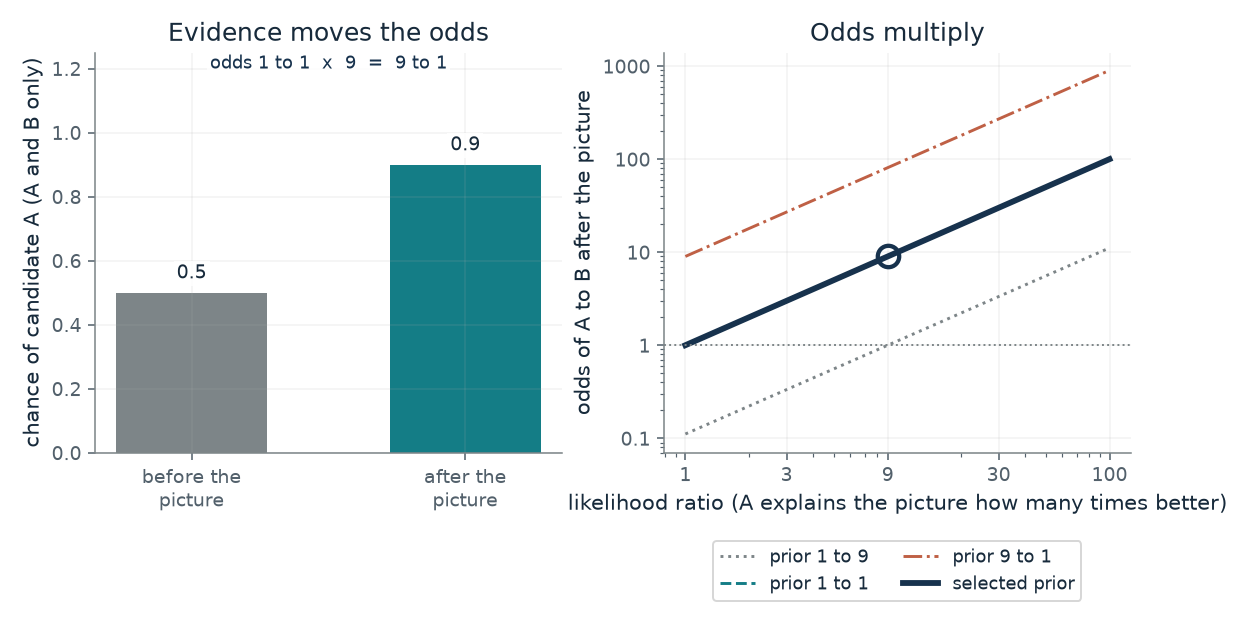

- **Prior odds:** 1 to 1
- **Likelihood ratio:** 9
- **Odds after the picture:** 9 to 1
- **Chance of A after the picture:** 0.9

Candidate A explains the picture 9 times as well as B and starts at odds 1 to 1, so the odds after the picture are 9 to 1. If A and B are the only cases, that is a chance of 0.9 for A, up from 0.5.

Posterior odds = likelihood ratio x prior odds = 9 x 1 = 9. Probability = odds/(1 + odds) = 9/10 = 0.9, valid only when A and B exclude each other and exhaust the cases.

In [2]:
figure, values, explanation = bayes_odds_picture(**{'likelihood_ratio': 9, 'prior_odds': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a picture change the odds between two candidates?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Likelihood ratio (A over B) = 9, Prior odds (A to B) = 1: Even prior odds times 9 give odds of 9 to 1 for A, a chance of 0.9 if A and B are the only cases. Now move the prior to 1 to 9: the nine-fold likelihood ratio exactly cancels it and the odds are 1 to 1.

**Takeaway:** Evidence multiplies the odds you started with, so a strong prior can offset strong evidence and a weak prior can be overturned by it.

**Why it matters:** The rest of the chapter asks where the prior comes from. This line is why it matters: one example can settle a question only because the learner arrives already holding odds.

**In brains and behavior:** A model that predicts behavior does not show that a person's brain uses the same machinery. The chapter says this of its Bayesian account.

**In machines:** A machine can apply the rule if its designer specifies priors and likelihoods; the arithmetic does not make a poorly specified model reliable.

**Where it applies:** Both candidates and the picture have nonzero probability, and the picture has nonzero likelihood under c'. Converting odds to a probability needs the two candidates to exclude each other and exhaust the cases.

**Check your understanding:** Priors 0.4 and 0.6 for A and B and likelihoods 0.75 and 0.25. What are the posterior odds for A?

<details><summary>Show the answer</summary>

Likelihood ratio 0.75/0.25 = 3, prior odds 0.4/0.6 = 2/3, so the posterior odds are 3 x 2/3 = 2, as in the book's derivation.

</details>

*Source: Chapter 11, One example was enough because the learner knew how characters are drawn. Book formula. The nine-to-one case with equal prior odds is the chapter's illustration; the chapter says it states the idea of the rule, not the exact score the paper computes. The other values are chosen here. The 2 to 3 prior with likelihood ratio 3 is the derivation's constructed check (posterior odds 2).*

## C11-D02: Why can fewer misses lose?

One rival misses the picture on 2 steady cells and another misses on 8 shaky cells. Which should a learner who knows the cells' habits prefer?

Two drawings of one character differ on a steady cell about 1 time in 10 and on a shaky cell about 4 times in 10. Taking the logarithm of how much more often a cell agrees than disagrees turns that into a score that adds across cells.

$$
w=\ln\frac{1-d}{d},\qquad d=2f(1-f)
$$

**Symbols:** f: the chance one drawing flips a cell; d: the chance two drawings of the same character differ on that cell; w: the weight a disagreement on that cell counts against a candidate

**Predict before looking:** Candidate 1 has 2 misses on steady cells and candidate 2 has 8 on shaky cells. Predict which wins when you count, and which when you weigh.

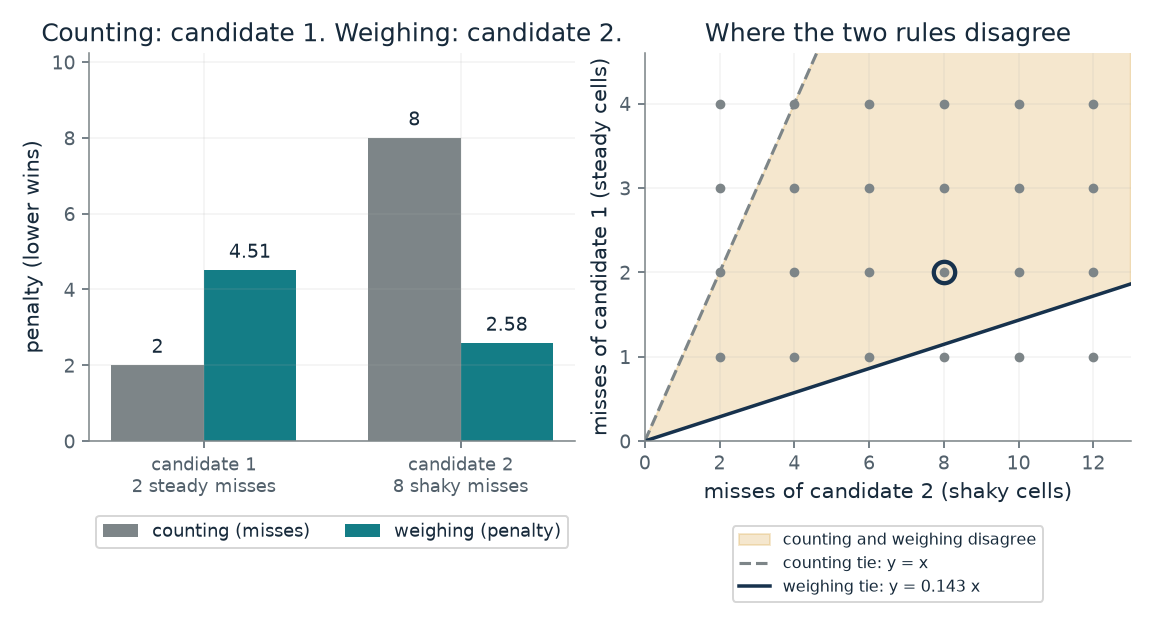

- **Weight on a steady cell:** 2.25
- **Weight on a shaky cell:** 0.323
- **Penalty, candidate 1 / candidate 2:** 4.51 / 2.58
- **Weighing picks:** candidate 2

A miss on a steady cell costs 2.25 and on a shaky cell 0.323. Candidate 1 has 2 steady misses and candidate 2 has 8 shaky ones, so counting picks candidate 1 and weighing picks candidate 2. This is a constructed toy, not data.

Steady cells flip 0.05 of the time, so twins differ with chance 2 x 0.05 x 0.95 = 0.095 and the weight is ln(0.905/0.095) = 2.25. Shaky cells: 2 x 0.3 x 0.7 = 0.42, weight 0.323. Penalties: 2 x 2.25 = 4.51 and 8 x 0.323 = 2.58.

In [3]:
figure, values, explanation = weighing_picture(**{'steady_misses': 2, 'shaky_misses': 8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can fewer misses lose?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Candidate 1 misses on steady cells = 2, Candidate 2 misses on shaky cells = 8: Counting picks candidate 1 (2 against 8). Weighing gives 2 x 2.25 = 4.51 against 8 x 0.323 = 2.58, so candidate 2 wins with four times the misses. Drop candidate 1 to a single steady miss and weighing flips back to candidate 1, at 2.25 against 2.58.

**Takeaway:** Knowing which cells are steady changes which misses count, so the learner with that knowledge can prefer the candidate with more misses.

**Why it matters:** This is the chapter's account of what a prior buys: it tells a learner which differences matter, so one picture can be sorted from many.

**In brains and behavior:** The chapter makes no claim that people weigh cells this way; it is an illustration of knowing how copies vary.

**In machines:** The weights are a specification a program can compute exactly, from the flip chances.

**Where it applies:** Cells are inked or blank with equal chance, flip independently across cells and between drawings, and the learner knows each cell's flip chance. Real characters are not grids of independent cells.

**Check your understanding:** How many shaky misses would candidate 2 need before weighing stops preferring it to a candidate with 2 steady misses?

<details><summary>Show the answer</summary>

Weighing ties when m x 0.323 = 2 x 2.25, so m is about 14. With whole misses, 14 shaky misses give 4.52 against 4.51 and the steady candidate wins by a hair.

</details>

*Source: Chapter 11, One example was enough because the learner knew how characters are drawn. The chapter's own simulated world: 40 cells, 20 steady (flip chance 0.05) and 20 shaky (0.30). The weights 2.25 and 0.32, and the penalties 4.5 and about 2.6, are the chapter's numbers recomputed. It is a toy, not a result from the paper.*

## C11-D03: How often does knowing which cells are steady pay off?

Over many 20-way trials, how much worse is counting agreements than weighing them, and does the gap shrink when all cells are equally steady?

Each trial draws a character, a picture and a twin as two noisy redraws of it, and unrelated rivals. The counting rule picks the candidate matching the most cells; the weighing rule picks the one with the lowest weighted penalty.

$$
\text{choose } c \text{ minimizing } \sum_{\text{cells } i} w_i\,[\,c_i \ne I_i\,]
$$

**Symbols:** w_i: the weight of cell i, equal to 1 when counting; c_i, I_i: the candidate's and the picture's value at cell i

**Predict before looking:** Predict the error of counting agreements and of weighing by steadiness for 20 candidates, and what happens when the shaky cells are as steady as the others.

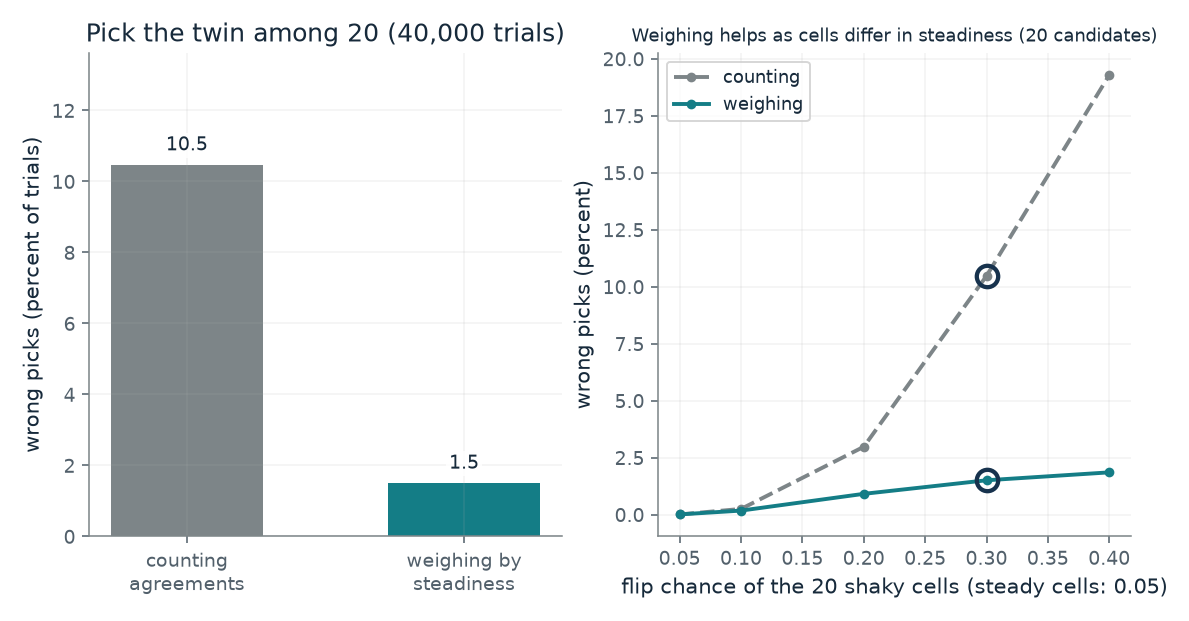

- **Counting, wrong picks (percent):** 10.5
- **Weighing, wrong picks (percent):** 1.5
- **Random pick would be wrong (percent):** 95
- **Counting errors per weighing error:** 6.96

In this seeded simulation of 40,000 trials, counting agreements picks the wrong twin 10.5 percent of the time and weighing by steadiness 1.5 percent, with shaky cells flipping 0.3 of the time. The chapter reports about 10.6 and 1.6 percent for 20 candidates and 0.30; this run is a constructed model, not a measurement.

Weights: steady 2.25, shaky 0.323. Each trial draws one 40-cell character, two redraws (picture and twin) and 19 unrelated grids; the lowest total penalty wins and ties are broken at random. Equal flip chances (0.05 and 0.05) give equal weights, so the two methods then agree exactly.

In [4]:
figure, values, explanation = simulation_picture(**{'shaky_flip': 0.3, 'candidates': 20})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How often does knowing which cells are steady pay off?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Flip chance of the 20 shaky cells = 0.3, Candidates to choose among = 20: Counting is wrong about 10.5 percent of the time and weighing about 1.5 percent in this seeded run, close to the chapter's 10.6 and 1.6. Slide the shaky chance down to 0.05 and the two methods become identical, since all weights are equal.

**Takeaway:** The benefit of weighing comes from the learner knowing how cells differ in steadiness; with nothing to know, it adds nothing.

**Why it matters:** It shows the prior doing real work in a controlled world, and that its value depends on how well it matches the world.

**In machines:** Both pickers are explicit procedures that a program applies; the second needs the flip chances as background knowledge.

**Where it applies:** The chapter's constructed world: independent 40-cell grids, 20 steady cells at 0.05, the rest at the shaky chance, other candidates unrelated characters, ties broken at random. A simulation is a computation with a stated model, not a measurement.

**Check your understanding:** If every cell had the same flip chance, why would counting and weighing give the same answers?

<details><summary>Show the answer</summary>

All weights would then be equal, so the weighted penalty is a constant times the count and ranks candidates the same way.

</details>

*Source: Chapter 11, One example was enough because the learner knew how characters are drawn. Simulation with disclosed seeds (11000 plus 10 times the shaky chance in percent plus the number of candidates), 40,000 trials per setting, written for this companion from the chapter's description. The chapter reports about 10.6 and 1.6 percent for 20 candidates and a shaky flip chance of 0.30. Not a result from the paper.*

## C11-D04: What did the one-shot character test report?

After one look at a new handwritten character, how often did people, a stroke model and a convolutional network pick its twin wrongly, and how did that change with less background?

The stroke model fitted numbers inside a fixed plan of strokes, parts and relations. Tripling its allowance for how much one copy differs from the standard form raised errors from 3.3 to 11.0 percent. A separate lesion to what it learned about how strokes are shaped, sized and joined left errors at 3.5.

$$
\text{errors}=100\times\frac{\text{wrong picks}}{\text{trials}}
$$

**Symbols:** errors: the percent of 20-way trials answered wrongly; random guessing: wrong 95 times in 100 among 20 candidates

**Predict before looking:** Predict whether the network's errors fall or rise when the background shrinks from 30 alphabets to five, and what that does to the stroke model.

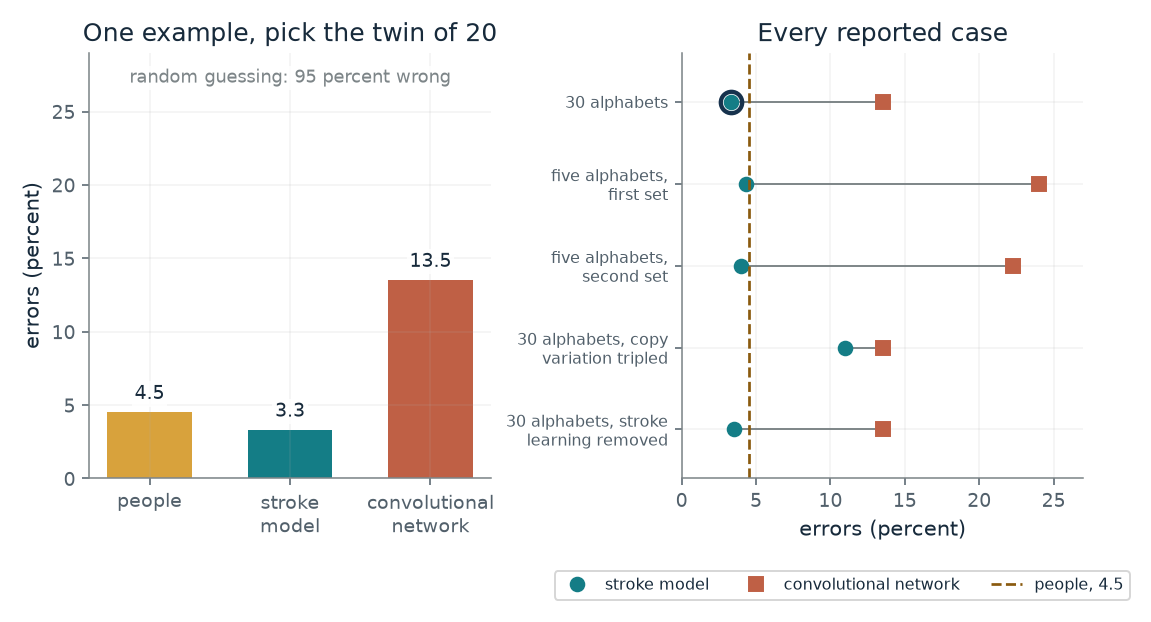

- **Stroke model errors (percent):** 3.3
- **Convolutional network errors (percent):** 13.5
- **People errors (percent):** 4.5
- **Network errors per stroke-model error:** 4.09

Reported errors for 30 alphabets: stroke model 3.3 percent, convolutional network 13.5 percent, people 4.5 percent. The chapter gives no split of how much each difference between the models mattered, and a lesion shows one learned part mattered, not that the whole prior did.

Network errors divided by stroke-model errors = 13.5/3.3 = 4.09. In the lesion rows the network figure is its intact 13.5, and the stroke figure is the lesioned model's.

In [5]:
figure, values, explanation = omniglot_picture(**{'scenario': '30 alphabets'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What did the one-shot character test report?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Case = five alphabets, first set: The stroke model rose only from 3.3 to 4.3 percent, while the network went from 13.5 to 24.0. Then pick the lesion that tripled copy variation: the stroke model's errors rise to 11.0, so knowing how copies vary was doing real work.

**Takeaway:** A built-in plan needed few earlier examples to fill in its numbers, and one learned part, how much copies vary, mattered a great deal. The reported results do not show that the whole prior did.

**Why it matters:** It is the chapter's evidence that a prior can make one example enough, and its warning that the gap between models is not all prior.

**In brains and behavior:** People averaged 4.5 percent errors. Accounts of how they did it are models, and the study does not show a mechanism.

**In machines:** The stroke model is a program with a designed structure (the authors call it prewired) and numbers learned from earlier characters; the network learned from pictures only.

**Where it applies:** Nothing is recomputed. The authors say the 4.5 percent for people may be an upper bound, since people answered quickly and had no incentive. The stroke model also had pen-stroke data the network never saw, and the two were trained on different tasks.

**Check your understanding:** Does the lesion result show that the whole prior accounts for the gap between 3.3 and 13.5 percent?

<details><summary>Show the answer</summary>

No. It shows that knowing how copies vary mattered. The stroke model also had pen strokes the network never saw, and the authors give no split of how much each difference mattered.

</details>

*Source: Chapter 11, One example was enough because the learner knew how characters are drawn. Reported results quoted from the chapter: Lake, Salakhutdinov and Tenenbaum (Science, 2015) and the 2019 progress report. 40 people on Mechanical Turk, ten trials each; the 3.5 percent figure for the stroke-learning lesion comes from the paper's supplement as cited in the chapter. The two five-alphabet sets are listed in the order the chapter gives them, and each used 136 or 156 characters.*

## C11-D05: How much did a manual change a first game?

How many times higher was the average first-game Frostbite score for players who read a manual than for players with no help?

The ratio divides a group's mean first-game score by the unaided group's. The scale in the 2015 paper sets random play at 0 and a professional tester at 100.

$$
\text{ratio}=\frac{\bar{S}_{\text{group}}}{\bar{S}_{\text{no help}}},\qquad \text{scaled}=100\times\frac{S-S_{\text{random}}}{S_{\text{tester}}-S_{\text{random}}}
$$

**Symbols:** S bar: a group's mean score in its first full game; S_random, S_tester: 65.2 for random play and 4335 for a professional tester, from the 2015 deep Q-network paper

**Predict before looking:** Predict the factor by which reading a manual raised the first-game score, and whether blurring the moving objects changed it.

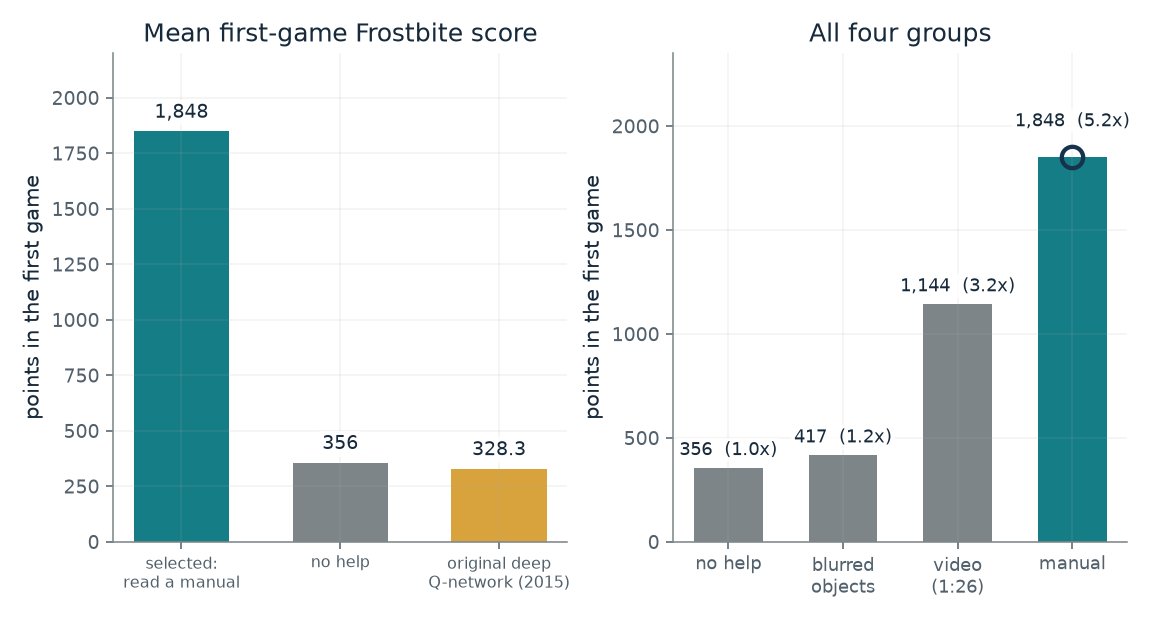

- **Mean first-game score:** 1,848
- **Times the no-help score:** 5.19
- **Players in the group:** 72
- **On the 2015 paper's scale (companion's conversion):** 41.8

Players in the group 'read a manual' averaged 1,848 points, 5.19 times the no-help 356. The chapter reads the manual result as a hint that people build a model of the game, which is the authors' interpretation; no mechanism was measured. The original deep Q-network scored 328.3, 6.2 on the 2015 scale.

Ratio = 1,848/356 = 5.19. Scale = 100 x (score - 65.2)/(4,335 - 65.2); for 328.3 this is 6.2, the 6.2 the 2015 paper reports. For the human groups the same conversion is this companion's own, and the two studies differ in training, players and setting.

In [6]:
figure, values, explanation = frostbite_picture(**{'group': 'manual'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much did a manual change a first game?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Group = manual: The manual group averaged 1,848 against 356: 5.19 times, the chapter's 5.2. Switch to blurred objects: 417, only 1.17 times, which the authors report as no detectable difference (p = 0.663).

**Takeaway:** A short manual was worth about five times the first-game score, but the reported data do not say what the manual changed in the players' minds.

**Why it matters:** It shows a head start that a learner can be given in words, and the chapter's caution that nobody has counted what each learner arrived with.

**In brains and behavior:** The players are people on Mechanical Turk, paid by score. The authors' remark about building a model of the game dynamics is an interpretation; no mechanism was measured.

**In machines:** The networks learn from game scores over about 920 hours of play, while the manual players had one session.

**Where it applies:** A short symposium paper comparing four Frostbite groups on first episodes only. The 328.3 is the original deep Q-network, not the Double DQN the authors compared; people and networks come to the game with different things already in place, so the comparison is not a fair count of what each learner had beforehand.

**Check your understanding:** The original network scored 328.3 against 65.2 for random play and 4335 for a professional tester. What is that on the 2015 scale?

<details><summary>Show the answer</summary>

100 x (328.3 - 65.2)/(4335 - 65.2) = 6.2, the figure in the 2015 paper.

</details>

*Source: Chapter 11, Players who read a manual scored 5.2 times higher in their first Frostbite game. Reported results quoted from the chapter and its sources: Tsividis and colleagues (2017) for the four group means (356, 417, 1,144 and 1,848) and group sizes; Mnih and colleagues (2015) for the 328.3 score and the 6.2 percent scale. The conversion of the human scores to the 2015 scale is this companion's own, to show the scale.*

## C11-D06: How sure can n successes make you?

After n successes in a row and no failures, how likely is another success, and how much of that answer is the prior?

Average the next trial's success chance over the belief about the unknown chance after n successes, which is proportional to p to the n under a uniform prior. The integral gives (n + 1)/(n + 2).

$$
P(\text{next success}\mid n\text{ successes})=\frac{n+1}{n+2}
$$

**Symbols:** n: the number of successes observed, with no failures; a: prior counts of success and failure; a = 1 is Laplace's uniform prior

**Predict before looking:** Predict the chance of another success after 1 and after 2 successes, then the failure chance after Laplace's 1,826,213.

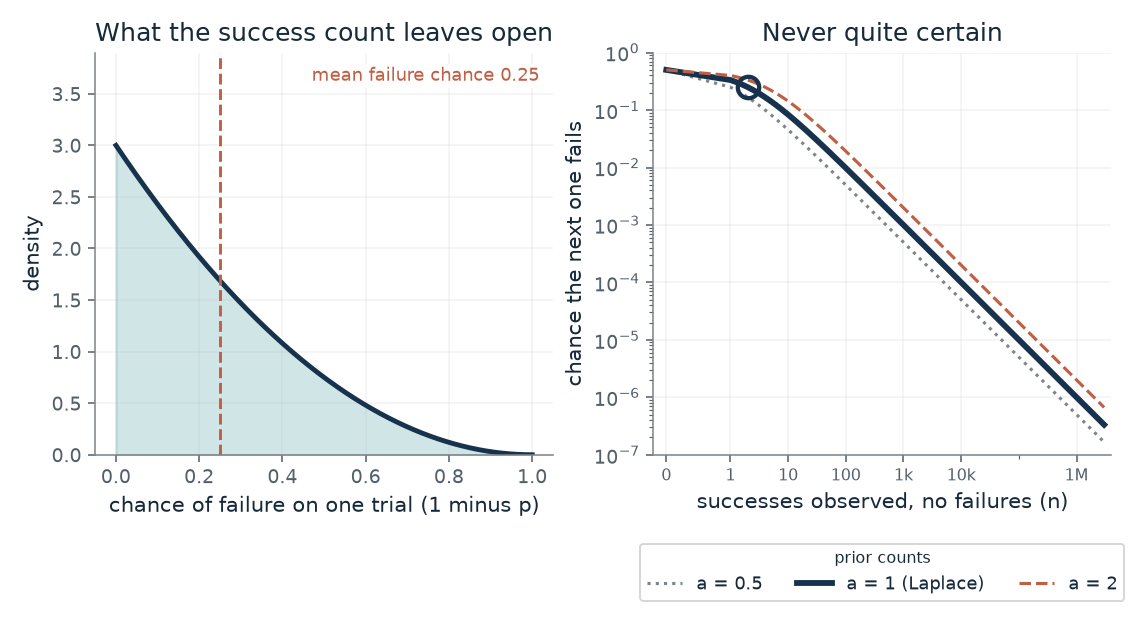

- **Chance of another success:** 0.75
- **Chance of failure:** 0.25
- **Odds for another success:** 3 to 1
- **Prior (pseudo-counts a):** 1 (the chapter's uniform prior)

After 2 successes and no failures, the uniform-prior rule gives 0.75 for another success. With prior counts a = 1 the answer is 0.75: the rule is a statement about the prior, not a measured chance. Only a = 1 is the chapter's rule; the other values are this companion's variation.

P(next success) = (n + a)/(n + 2a) = (2 + 1)/(2 + 2) = 0.75; for a = 1 this is (n + 1)/(n + 2).

In [7]:
figure, values, explanation = succession_picture(**{'n': 2, 'prior_count': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How sure can n successes make you?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Successes observed (n) = 2, Prior counts (a) = 1: After 1 success the chance is 2 in 3 and after 2 it is 3 in 4, exactly the derivation's check. Move n to 1,826,213 and the odds are 1,826,214 to 1. Then change the prior counts at the same n: the answer changes with the prior.

**Takeaway:** Each success raises the prediction but never reaches certainty, and the number is as much about the prior as about the data.

**Why it matters:** It shows how a stated assumption about the world turns a count into a confident prediction.

**In brains and behavior:** Laplace's example shows a mathematician's reasoning, not a measurement of how people judge the sun.

**In machines:** A system can apply the rule to a simple binary event when its assumptions are defensible, and should also consider failures and changes over time.

**Where it applies:** A fixed but unknown chance of success, independent trials given that chance, and a uniform prior on it. A figure like Laplace's is a statement about a prior, not a measured chance.

**Check your understanding:** A system has seen 9 successes and no failures. What does the rule predict, and what must hold for it to be sensible?

<details><summary>Show the answer</summary>

(9 + 1)/(9 + 2) = 10/11, or 0.909. It needs a fixed chance, independent trials and a uniform prior, and it ignores any change in the process.

</details>

*Source: Chapter 11, A strong guess about the world speeds learning until the world disagrees. Book formula and Laplace's 1814 figures (1,826,213 days, odds 1,826,214 to one) as the chapter quotes them. The prior counts a other than 1 are this companion's variation, using the standard result for a symmetric prior, to show that the answer depends on the prior.*

## C11-D07: What does a strong prior cost when it is wrong?

Two examples fit 64 of 256 possible rules. A learner who favors one-switch rules is nearly certain after them. How does it fare when the hidden rule is one of those, and when it is not?

Keep only the rules that fit the examples and renormalize the belief. The learner's chance on an unseen setting is the total belief of the rules that match the hidden rule there.

$$
\text{belief}(r\mid\text{examples})\propto \text{prior}(r)\cdot[\,r\text{ fits all examples}\,]
$$

**Symbols:** r: one of the 256 rules, a yes or no for each of the 8 switch settings; prior(r): flat: 1/256 each. Soft bias: the favored share split over the six one-switch rules, the rest over the other 250

**Predict before looking:** After the two examples, predict the learner's average probability on the right answers if the hidden rule is the first-switch rule, and if it is parity.

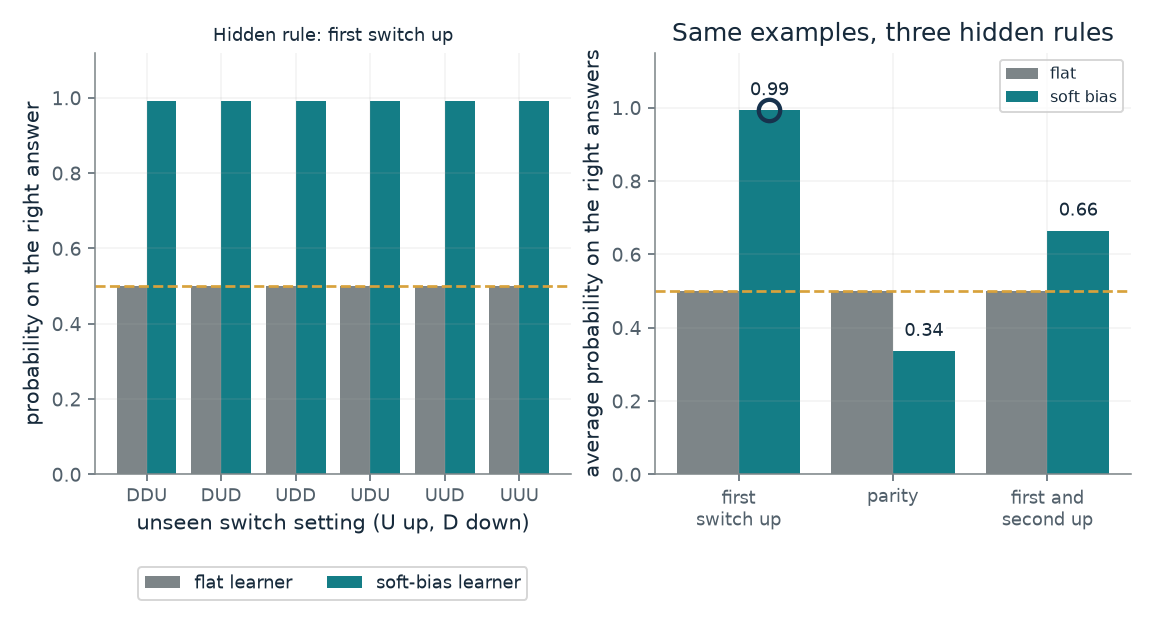

- **Soft-bias learner, average on the right answers:** 0.992
- **Flat learner, average on the right answers:** 0.5
- **Rules still consistent (of 256):** 64
- **Belief on the six one-switch rules:** 0.985

After the examples (DDD is no, DUU is no) the soft-bias learner puts 0.985 of its belief on the one-switch rules and scores 0.992 on the unseen settings; the flat learner scores 0.5. Averaged over all 256 possible hidden rules both would score exactly 0.5. This is a constructed toy.

64 of 256 rules fit the 2 examples. Soft-bias prior: 0.99 split over 6 one-switch rules, 0.01 over the other 250. Chance on an unseen setting = total posterior belief of rules that give the hidden rule's answer there; the bars average these.

In [8]:
figure, values, explanation = switch_picture(**{'hidden_rule': 'first switch up', 'examples': 2, 'simple_share': 0.99})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a strong prior cost when it is wrong?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Hidden rule = odd number of switches up (parity), Examples shown = 2, Belief in one-switch rules = 0.99: With parity hidden the biased learner is nearly sure of the first-switch rule and averages only 0.34 on the right answers, worse than a coin. Set the examples to 3 and its prediction falls back to 0.5.

**Takeaway:** A strong prior is a gift when the world fits it and a trap when it does not, and averaged over all possible rules it gains nothing.

**Why it matters:** It is the chapter's honest ledger for one-shot learning: the head start and its price.

**In machines:** Both learners are exact Bayesian calculations over a list of rules; the bias is a design choice, not something learned here.

**Where it applies:** Three two-way switches, every setting's answer given by the hidden rule, and no noise. The third example's answer comes from whichever hidden rule is chosen. The chapter's 'no free lunch' remark rests on Wolpert and Macready's result for search problems and does not say the same balance holds for the real world.

**Check your understanding:** Why does the flat learner average exactly 0.5 on every unseen setting?

<details><summary>Show the answer</summary>

Among the rules that fit the examples, half say yes and half say no on any setting that was not shown, so its belief on each answer is one half.

</details>

*Source: Chapter 11, A strong guess about the world speeds learning until the world disagrees. The chapter's own simulated world, computed exactly by listing all 256 rules; not a result from any paper. The examples are all switches down, first down with the other two up, and for the third example first and third up with the second down; each answer is the hidden rule's own (no, no, and no for parity, as in the chapter).*

## C11-D08: Which test case can separate two rules?

Several rules explain every example so far. Which new item could the answer actually tell apart?

A triple that fits 'intervals of two' also fits the true rule, so hearing yes teaches nothing about which is right. Only a triple the narrow rule forbids but the true rule accepts can eliminate it.

$$
\text{informative} \iff \text{rule}_1(x)\ne\text{rule}_2(x)
$$

**Symbols:** rule_1, rule_2: two rival rules, such as the true rule and a narrower one; x: a new triple or prompt

**Predict before looking:** Predict whether 10 12 14, 1 3 13 and 3 2 1 can each tell 'increasing' from 'gaps of two'.

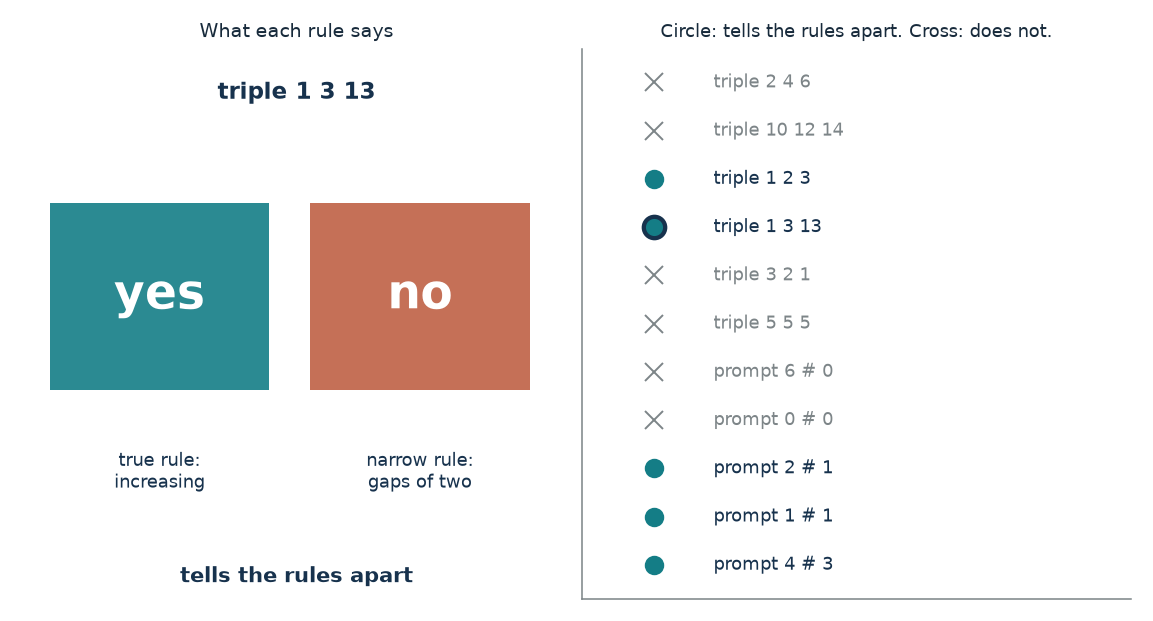

- **Item:** triple 1 3 13
- **Rule 1 says:** yes (true rule)
- **Rule 2 says:** no (narrow rule)
- **Tells the rules apart:** yes

For the triple 1 3 13, the true rule (increasing order) says yes and the narrow rule (gaps of two) says no. Only a triple that one rule forbids and the other accepts can split them. Wason's students and rules are the chapter's account of his 1960 study.

True rule: first < second < third. Narrow rule: second - first = 2 and third - second = 2. Compare the two answers.

In [9]:
figure, values, explanation = test_item_picture(**{'item': 'triple 1 3 13'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Which test case can separate two rules?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Test item = triple 1 3 13: Only 1 3 13 splits the rules here: the true rule says yes and the narrow rule no. The triple 10 12 14 fits both and 3 2 1 fails both, so neither teaches anything. Then try the prompt 2 # 1, which separates addition from 'first plus twice the second'.

**Takeaway:** An example that every candidate rule explains teaches nothing, and a test case is an input chosen to make the rules disagree.

**Why it matters:** It gives a way to check any confident answer, from a person or a machine: ask for a case where the favored rule and a rival differ.

**In brains and behavior:** Wason's students mostly tested triples that fit their own guess. That is the chapter's account of one lab task, not a law of how people reason.

**In machines:** The # prompt is an invented illustration; no system was tested.

**Where it applies:** Two rival rules only. The chapter notes the puzzle was built to trap confirming evidence, so it does not measure everyday reasoning, and the coding of each student's reasons was Wason's own. A finite set of answers cannot prove no unimagined rule also fits.

**Check your understanding:** Why does the prompt 6 # 0 teach nothing about addition versus 'first plus twice the second'?

<details><summary>Show the answer</summary>

The second number is 0, so both rules give 6. The three given examples all had a second number of 0 for the same reason.

</details>

*Source: Chapter 11, An example that every candidate rule explains teaches nothing. Wason's 1960 puzzle as the chapter reports it: the true rule is three numbers in increasing order, and the narrower rule is intervals of two. 29 students: 6 announced the right rule first, 22 a wrong one, one none; 21 found the right one in the end. The prompt with the # symbol is the chapter's own invention, as it says; no system was tested.*

## Bring it to your own question

Use these ideas to ask what prior a confident answer rests on, to choose a test case that separates rival rules, and to read a one-shot result without crediting the whole gap to the prior.

Use the `mmi-ch11-learning-from-little` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.